# Лабораторная работа №2 — классификация Titanic

**Цель:** по признакам пассажира предсказать `Survived` (1 — выжил). Основная метрика — F1 для класса 1, порог ТЗ — **F1 > 0,70**. Также оцениваем Accuracy, Precision, Recall и матрицы ошибок.

**Протокол:** стратифицированное разбиение 80% train / 20% test, `random_state=42`. Настройки сравнивались с помощью 5-кратной CV внутри train. Локальный test неоднократно просматривался во время опытов, поэтому его оценка исследовательская. Результат на единой выборке группы пока неизвестен.

[ТЗ курса](https://github.com/lesopylka/ml_course_mai/blob/39d3023809a246853db83f4ec3b39c9798e5dfd1/classification/lab02.pdf) · [Titanic Dataset](https://www.kaggle.com/datasets/yasserh/titanic-dataset)

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (accuracy_score, confusion_matrix, ConfusionMatrixDisplay,
                             f1_score, precision_score, recall_score)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

RANDOM_STATE = 42
data = pd.read_csv(Path('data/Titanic-Dataset.csv'))
print(f'Размер: {data.shape[0]} строк × {data.shape[1]} столбцов')
display(data.head(3))

Размер: 891 строк × 12 столбцов


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S


## 1. Первичный анализ

Проверяем типы, пропуски, дубликаты и баланс классов до разбиения. Эти описательные сводки не используются для настройки преобразований и моделей.

In [2]:
schema = pd.DataFrame({'тип': data.dtypes.astype(str), 'пропуски': data.isna().sum(),
                       'уникальных': data.nunique(dropna=True)})
display(schema)
display(data[['Age','Fare','SibSp','Parch']].describe(percentiles=[0.25,0.5,0.75,0.95]).round(1))
print('Полных дублей:', data.duplicated().sum(),
      '| дублей PassengerId:', data.PassengerId.duplicated().sum(),
      '| повторяющихся Ticket:', data.Ticket.duplicated().sum())
display(data.Survived.value_counts().rename(index={0:'не выжил',1:'выжил'}).to_frame('пассажиров'))
rates = pd.concat({c: data.groupby(c, dropna=False).Survived.agg(['size','mean'])
                   for c in ['Sex', 'Pclass', 'Embarked']})
display(rates.rename(columns={'size':'пассажиров','mean':'доля выживших'}).round(3))

,тип,пропуски,уникальных
PassengerId,int64,0,891
Survived,int64,0,2
Pclass,int64,0,3
Name,str,0,891
Sex,str,0,2
Age,float64,177,88
SibSp,int64,0,7
Parch,int64,0,7
Ticket,str,0,681
Fare,float64,0,248


,Age,Fare,SibSp,Parch
count,714.0,891.0,891.0,891.0
mean,29.7,32.2,0.5,0.4
std,14.5,49.7,1.1,0.8
min,0.4,0.0,0.0,0.0
25%,20.1,7.9,0.0,0.0
50%,28.0,14.5,0.0,0.0
75%,38.0,31.0,1.0,0.0
95%,56.0,112.1,3.0,2.0
max,80.0,512.3,8.0,6.0


Полных дублей: 0 | дублей PassengerId: 0 | повторяющихся Ticket: 210


,пассажиров
Survived,
не выжил,549
выжил,342


пассажиров  доля выживших
Sex      female         314          0.742
         male           577          0.189
Pclass   1              216          0.630
         2              184          0.473
         3              491          0.242
Embarked C              168          0.554
         Q               77          0.390
         S              644          0.337
         NaN              2          1.000

**Вывод.** 891 пассажир, 342 выжили (38,4%). Пропуски есть в `Age` (177), `Cabin` (687) и `Embarked` (2); полных дублей и повторов `PassengerId` нет. Билеты повторяются у разных пассажиров, поэтому `Ticket` не используем как идентификатор. Доля выживших выше среди женщин и пассажиров первого класса; это ассоциации, а не доказательство причинности. `PassengerId` — уникальный номер, `Name` и `Ticket` способны запоминать людей/семьи, `Cabin` почти целиком отсутствует и может косвенно кодировать размещение. Полные `PassengerId`, `Name`, `Ticket` и `Cabin` исключаем. Для дерева решений отдельно используем только обращение, извлечённое из имени; `Survived` никогда не входит в признаки.

## 2. Разбиение и подготовка

Для дерева из имени выделяем обращение `Mr`, `Mrs`, `Miss`, `Master` или `Other`. Другие модели используют исходные семь признаков. В KNN пропуски возраста заполняем медианой по полу и классу, а `Pclass` кодируем как категорию. В остальных моделях числовые пропуски заменяем медианой train, `Pclass` оставляем числом. Категориальные пропуски заполняем модой, категории кодируем One-Hot с обработкой новых значений. Стандартизация внутри pipeline нужна SVM (зазор) и KNN (расстояние); деревьям масштаб не нужен. Повторяющийся `Ticket` исключён из признаков, а строки с одним билетом соответствуют разным пассажирам; используем требуемый стратифицированный split.

In [3]:
numeric = ['Pclass', 'Age', 'SibSp', 'Parch', 'Fare']
categorical = ['Sex', 'Embarked']
features = numeric + categorical
title = data['Name'].str.extract(r',\s*([^.]*)\.', expand=False).str.strip()
data['Title'] = title.where(title.isin(['Mr', 'Mrs', 'Miss', 'Master']), 'Other')
X = data[features + ['Title']]
y = data['Survived']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)
assert 'Survived' not in X.columns and X_train.index.intersection(X_test.index).empty
print(pd.DataFrame({'объектов': [len(y_train), len(y_test)],
                    'доля класса 1': [y_train.mean(), y_test.mean()]}, index=['train', 'test']).round(3))

from sklearn.base import BaseEstimator, TransformerMixin

class GroupAgeImputer(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        self.group_medians_ = X.groupby(['Sex', 'Pclass']).Age.median()
        self.median_ = X.Age.median()
        return self

    def transform(self, X):
        result = X.copy()
        groups = pd.MultiIndex.from_frame(result[['Sex', 'Pclass']])
        medians = pd.Series(self.group_medians_.reindex(groups).to_numpy(), index=result.index)
        result['Age'] = result.Age.fillna(medians).fillna(self.median_)
        return result

def make_preprocessor(scale=False, include_title=False, class_cat=False):
    num_steps = [('impute', SimpleImputer(strategy='median'))]
    if scale:
        num_steps.append(('scale', StandardScaler()))
    return ColumnTransformer([
        ('num', Pipeline(num_steps), [c for c in numeric if not (class_cat and c == 'Pclass')]),
        ('cat', Pipeline([('impute', SimpleImputer(strategy='most_frequent')),
                          ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]),
         categorical + (['Title'] if include_title else []) + (['Pclass'] if class_cat else []))
    ])

       объектов  доля класса 1
train       712          0.383
test        179          0.385


## 3. Baseline и модели

`DummyClassifier` предсказывает наиболее частый класс. Для дерева зафиксированы обращение из имени, критерий Джини, глубина 4, минимум 5 строк в листе и веса классов `{0: 1, 1: 1.5}`. Для KNN — `k=21`, равные голоса, евклидово расстояние и описанная выше обработка признаков. Для леса, бустинга и SVM используется подбор параметров на train по среднему F1 на пяти сгибах. История сравнения вариантов — в [PLAN.md](PLAN.md).

In [4]:
baseline = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)
specs = {
    'Decision Tree': (DecisionTreeClassifier(random_state=RANDOM_STATE),
                      {'model__max_depth':[4], 'model__min_samples_leaf':[5],
                       'model__criterion':['gini'], 'model__class_weight':[{0: 1, 1: 1.5}]}, False),
    'Random Forest': (RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1),
                      {'model__max_depth':[5,None], 'model__min_samples_leaf':[1,3,5]}, False),
    'Gradient Boosting': (GradientBoostingClassifier(random_state=RANDOM_STATE),
                          {'model__n_estimators':[100,200], 'model__max_depth':[2,3],
                           'model__learning_rate':[0.05,0.1]}, False),
    'SVM': (SVC(), {'model__C':[0.5,1,2,5], 'model__kernel':['rbf']}, True),
    'KNN': (KNeighborsClassifier(), {'model__n_neighbors':[21],
                                     'model__weights':['uniform'], 'model__p':[2]}, True),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
searches = {}
for name, (model, grid, scale) in specs.items():
    steps = []
    if name == 'KNN':
        steps.append(('age_groups', GroupAgeImputer()))
    steps.extend([('prep', make_preprocessor(scale, include_title=(name == 'Decision Tree'), class_cat=(name == 'KNN'))), ('model', model)])
    search = GridSearchCV(Pipeline(steps), grid, scoring='f1', cv=cv, n_jobs=-1)
    search.fit(X_train, y_train)
    searches[name] = search
cv_table = pd.DataFrame([{'модель':name, 'CV F1':s.best_score_}
                         for name,s in searches.items()]).sort_values('CV F1', ascending=False)
display(cv_table.round(3))
for name, search in searches.items():
    print(name, search.best_params_)
selected_name = cv_table.iloc[0]['модель']
print('Лучшая модель по CV:', selected_name)

,модель,CV F1
2,Gradient Boosting,0.764
4,KNN,0.759
0,Decision Tree,0.756
1,Random Forest,0.749
3,SVM,0.748


Decision Tree {'model__class_weight': {0: 1, 1: 1.5}, 'model__criterion': 'gini', 'model__max_depth': 4, 'model__min_samples_leaf': 5}
Random Forest {'model__max_depth': None, 'model__min_samples_leaf': 3}
Gradient Boosting {'model__learning_rate': 0.1, 'model__max_depth': 3, 'model__n_estimators': 200}
SVM {'model__C': 0.5, 'model__kernel': 'rbf'}
KNN {'model__n_neighbors': 21, 'model__p': 2, 'model__weights': 'uniform'}
Лучшая модель по CV: Gradient Boosting


## 4. Сравнение на локальном test

F1 — гармоническое среднее Precision и Recall. В матрицах строки — истинный класс, столбцы — прогноз. **FP** — предсказали выживание погибшему пассажиру, **FN** — предсказали гибель выжившему.

,Accuracy,Precision,Recall,F1,F1 > 0.70
Dummy,0.615,0.000,0.000,0.000,False
Decision Tree,0.827,0.779,0.768,0.774,True
Random Forest,0.821,0.849,0.652,0.738,True
Gradient Boosting,0.816,0.821,0.667,0.736,True
SVM,0.827,0.817,0.710,0.760,True
KNN,0.793,0.786,0.638,0.704,True


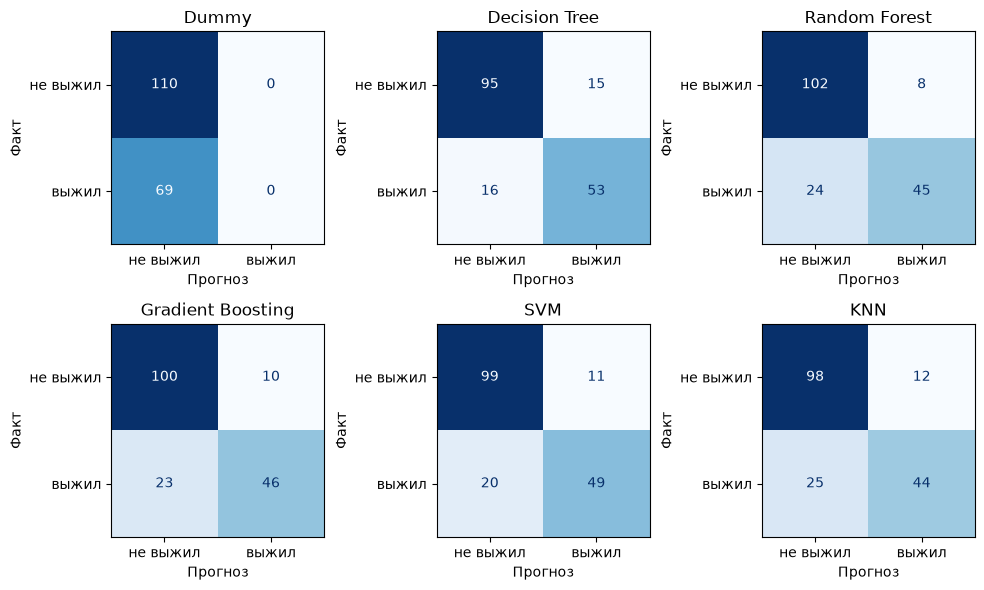

Decision Tree F1 train/test: 0.79 / 0.774


In [5]:
models = {'Dummy': baseline, **{name:s.best_estimator_ for name,s in searches.items()}}
def evaluate(model):
    pred = model.predict(X_test)
    return {'Accuracy':accuracy_score(y_test,pred),
            'Precision':precision_score(y_test,pred,zero_division=0),
            'Recall':recall_score(y_test,pred,zero_division=0),
            'F1':f1_score(y_test,pred,zero_division=0)}

scores = pd.DataFrame({name:evaluate(model) for name,model in models.items()}).T
scores['F1 > 0.70'] = scores.F1 > 0.70
display(scores.round(3))
fig, axes = plt.subplots(2, 3, figsize=(10, 6))
for ax, (name, model) in zip(axes.flat, models.items()):
    cm = confusion_matrix(y_test, model.predict(X_test), labels=[0,1])
    ConfusionMatrixDisplay(cm, display_labels=['не выжил','выжил']).plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(name)
    ax.set_xlabel('Прогноз')
    ax.set_ylabel('Факт')
plt.tight_layout()
plt.show()
tree = models['Decision Tree']
print('Decision Tree F1 train/test:', round(f1_score(y_train,tree.predict(X_train)),3),
      '/', round(scores.loc['Decision Tree','F1'],3))

**Вывод.** Dummy всегда выбирает класс 0 и не находит выживших. На локальном test все пять моделей превышают F1 0,70. Дерево и KNN улучшались после просмотра этого test, поэтому результат исследовательский. По среднему F1 на train-CV выбран Gradient Boosting. Дерево дополнительно использует обращение из имени, а KNN — отдельную обработку возраста и класса билета.

## 5. Важность признаков

Важности One-Hot столбцов суммируются до признаков `Sex`, `Embarked` и `Title`. Обращение `Title` включено только в дерево решений, поэтому его значение для двух ансамблей равно нулю. Это важность для данного алгоритма, а не причинный эффект; встроенные важности деревьев могут завышать вклад непрерывных признаков и делить вклад между коррелирующими.

,Decision Tree,Random Forest,Gradient Boosting
Sex,0.000,0.424,0.421
Fare,0.215,0.198,0.216
Age,0.007,0.156,0.168
Pclass,0.109,0.118,0.140
SibSp,0.000,0.034,0.028
Embarked,0.019,0.041,0.024
Parch,0.000,0.029,0.003
Title,0.650,0.000,0.000


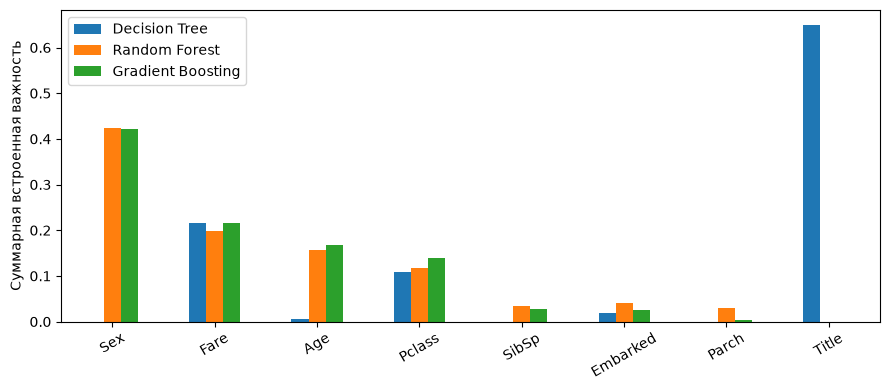

In [6]:
importance = {}
for name in ['Decision Tree', 'Random Forest', 'Gradient Boosting']:
    pipe = models[name]
    names = pipe.named_steps['prep'].get_feature_names_out()
    values = pipe.named_steps['model'].feature_importances_
    importance[name] = {feature: values[[n == f'num__{feature}' or n.startswith(f'cat__{feature}_')
                                  for n in names]].sum() for feature in features + ['Title']}
imp = pd.DataFrame(importance).sort_values('Gradient Boosting', ascending=False)
display(imp.round(3))
imp.plot.bar(figsize=(9,4), rot=30, ylabel='Суммарная встроенная важность')
plt.tight_layout()
plt.show()

**Вывод.** Для дерева решений наиболее важны обращение `Title` (0,650), тариф (0,215) и класс билета (0,109). Обращение связано с полом, поэтому важность может распределяться между этими признаками. В ансамблях обращение не использовалось. Доли выживших по полу и классу различались уже в EDA; важность признака не доказывает причинную связь.

## 6. Ошибки модели, выбранной по CV

Групповые доли ошибок смотрим вместе с числом объектов: малые группы дают нестабильные оценки. Отдельные строки иллюстрируют неопределённость прогноза, но не позволяют восстановить реальные обстоятельства спасения.

In [7]:
chosen = models[selected_name]
detail = X_test.copy()
detail.insert(0, 'PassengerId', data.loc[X_test.index,'PassengerId'])  # только для показа строки
detail['истина'] = y_test
detail['прогноз'] = chosen.predict(X_test)
detail['ошибка'] = detail['истина'] != detail['прогноз']
cm = confusion_matrix(detail['истина'], detail['прогноз'], labels=[0,1])
print(f'{selected_name}: TN={cm[0,0]}, FP={cm[0,1]}, FN={cm[1,0]}, TP={cm[1,1]}')
detail['возраст'] = pd.cut(detail.Age, bins=[0,18,40,65,np.inf],
                          labels=['0–18','19–40','41–65','66+']).cat.add_categories('не указан').fillna('не указан')
for group in ['Sex','Pclass','возраст']:
    print('\nОшибки по', group)
    display(detail.groupby(group, dropna=False)['ошибка'].agg(['size','mean'])
            .rename(columns={'size':'пассажиров','mean':'доля ошибок'}).round(3))
mistakes = pd.concat([detail[(detail.истина==0)&(detail.прогноз==1)].head(3),
                      detail[(detail.истина==1)&(detail.прогноз==0)].head(3)])
display(mistakes[['PassengerId','Pclass','Sex','Age','SibSp','Parch','Fare','Embarked','истина','прогноз']])

Gradient Boosting: TN=100, FP=10, FN=23, TP=46

Ошибки по Sex


,пассажиров,доля ошибок
Sex,,
female,61,0.180
male,118,0.186



Ошибки по Pclass


,пассажиров,доля ошибок
Pclass,,
1,45,0.222
2,34,0.118
3,100,0.190



Ошибки по возраст


,пассажиров,доля ошибок
возраст,,
0–18,31,0.161
19–40,79,0.177
41–65,28,0.214
66+,1,0.000
не указан,40,0.200


,PassengerId,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,истина,прогноз
536,537,1,male,45.0,0,0,26.5500,S,0,1
698,699,1,male,49.0,1,1,110.8833,C,0,1
297,298,1,female,2.0,1,2,151.5500,S,0,1
553,554,3,male,22.0,0,0,7.2250,C,1,0
559,560,3,female,36.0,1,0,17.4000,S,1,0
279,280,3,female,35.0,1,1,20.2500,S,1,0


**Вывод.** У бустинга 23 FN и 10 FP. Среди выживших он чаще ошибается, чем ошибочно предсказывает выживание невыжившему. В тесте доля ошибок по полу около 18%, по классу — от 12% до 22%; в группе старше 65 лет лишь один человек. Например, неверные прогнозы для пассажиров №537 и №554 могут быть связаны с тем, что класс билета и другие доступные признаки не описывают всех обстоятельств. Это возможное объяснение, а не установленная причина.

В бустинг не входят идентификаторы, имена, билеты, каюты и целевая переменная. Повторяющиеся билеты у разных пассажиров могут означать связанные группы, что ограничивает независимость оценки.

## 7. Что объяснить на защите

- **Подготовка.** Заполняем пропуски и кодируем категории внутри pipeline на train. Для SVM и KNN масштабируем числовые признаки, потому что их масштаб влияет на границу и расстояния.
- **Сравнение.** Один split для всех моделей. Параметры подбирались внутри train с помощью CV. Средний CV F1 бустинга — 0,764, дерева — 0,756, KNN — 0,759. Это оценки после подбора и их следует рассматривать с осторожностью.
- **Улучшения.** Дерево с обращением из имени, весами классов и меньшей глубиной дало F1 0,756 на пяти сгибах против 0,732 у прежнего дерева. Для KNN категориальный класс билета и медиана возраста по группам дали 0,759 против 0,744. На двух других разбиениях преимущество KNN не повторилось.
- **Модели.** Дерево строит правила, лес усредняет деревья, бустинг последовательно добавляет поправки, SVM ищет разделяющую границу, KNN голосует по ближайшим объектам.
- **Ограничения.** F1 учитывает Precision и Recall, но не TN. Важность признака не доказывает причинность. Локальный test использовался повторно, а результат на едином test группы ещё неизвестен.